In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/inception_v3_weights/keras/default/1/inception_v3_weights_tf_dim_ordering_tf_kernels_notop.h5
/kaggle/input/flickr8k/captions.txt
/kaggle/input/flickr8k/Images/3226254560_2f8ac147ea.jpg
/kaggle/input/flickr8k/Images/214543992_ce6c0d9f9b.jpg
/kaggle/input/flickr8k/Images/2366643786_9c9a830db8.jpg
/kaggle/input/flickr8k/Images/3368819708_0bfa0808f8.jpg
/kaggle/input/flickr8k/Images/2190227737_6e0bde2623.jpg
/kaggle/input/flickr8k/Images/2752809449_632cd991b3.jpg
/kaggle/input/flickr8k/Images/3097776588_312932e438.jpg
/kaggle/input/flickr8k/Images/1206506157_c7956accd5.jpg
/kaggle/input/flickr8k/Images/1319634306_816f21677f.jpg
/kaggle/input/flickr8k/Images/2465218087_fca77998c6.jpg
/kaggle/input/flickr8k/Images/3351493005_6e5030f596.jpg
/kaggle/input/flickr8k/Images/2949337912_beba55698b.jpg
/kaggle/input/flickr8k/Images/534886684_a6c9f40fa1.jpg
/kaggle/input/flickr8k/Images/3543600125_223747ef4c.jpg
/kaggle/input/flickr8k/Images/2174206711_11cb712a8d.jpg
/kaggle/input/flic

In [2]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import plotly.graph_objects as go
import re
import tensorflow as tf
from tensorflow.keras.applications.inception_v3 import InceptionV3
from tensorflow.keras.preprocessing.image import img_to_array, load_img
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical, plot_model
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Input, Dense, LSTM, Embedding, add
from tensorflow.keras.layers import Flatten, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, LearningRateScheduler
from sklearn.model_selection import train_test_split
from nltk.translate.bleu_score import corpus_bleu
from PIL import Image
from tqdm import tqdm_notebook
from collections import Counter

2025-05-29 10:18:33.353860: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1748513913.636148      35 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1748513913.715832      35 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
# Path to the images
images_directory = '/kaggle/input/flickr8k/Images/'
# Path to the captions
captions_path = '/kaggle/input/flickr8k/captions.txt'

In [4]:
def load_captions(file_path):
    with open(file_path, 'r') as f:
        captions = f.readlines()
        # Lowercasing  the captions
        captions = [caption.lower() for caption in captions[1:]]
    return captions

def tokenize_captions(captions):
    tokenizer = Tokenizer()
    tokenizer.fit_on_texts(captions)
    return tokenizer

# Loading the captions from the dataset
captions = load_captions(captions_path)
captions[:15:3]

['1000268201_693b08cb0e.jpg,a child in a pink dress is climbing up a set of stairs in an entry way .\n',
 '1000268201_693b08cb0e.jpg,a little girl climbing the stairs to her playhouse .\n',
 '1001773457_577c3a7d70.jpg,a black dog and a tri-colored dog playing with each other on the road .\n',
 '1001773457_577c3a7d70.jpg,two dogs on pavement moving toward each other .\n',
 '1002674143_1b742ab4b8.jpg,a small girl in the grass plays with fingerpaints in front of a white canvas with a rainbow on it .\n']

In [5]:
def clean_text(text):
    # Removing punctuation marks
    text = re.sub(r'[^\w\s]', '', text)
    
    # Removing numbers
    text = re.sub(r'\d+', '', text)
    
    # Removing extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

# Cleaning the captions
cleaned_captions = [clean_text(caption.split(',')[1]) for caption in captions]
cleaned_captions[:15:2]

['a child in a pink dress is climbing up a set of stairs in an entry way',
 'a little girl climbing into a wooden playhouse',
 'a little girl in a pink dress going into a wooden cabin',
 'a black dog and a tricolored dog playing with each other on the road',
 'two dogs of different breeds looking at each other on the road',
 'a little girl covered in paint sits in front of a painted rainbow with her hands in a bowl',
 'a small girl in the grass plays with fingerpaints in front of a white canvas with a rainbow on it',
 'young girl with pigtails painting outside in the grass']

In [6]:
# Image ID + \t + Caption
captions_IDs = []
for i in range(len(cleaned_captions)):
    #  Adding 'start' word and 'end' word to the captions
    item = captions[i].split(',')[0]+'\t'+'start '+cleaned_captions[i]+' end\n'
    captions_IDs.append(item)
    
captions_IDs[:20:3], len(captions_IDs)

(['1000268201_693b08cb0e.jpg\tstart a child in a pink dress is climbing up a set of stairs in an entry way end\n',
  '1000268201_693b08cb0e.jpg\tstart a little girl climbing the stairs to her playhouse end\n',
  '1001773457_577c3a7d70.jpg\tstart a black dog and a tricolored dog playing with each other on the road end\n',
  '1001773457_577c3a7d70.jpg\tstart two dogs on pavement moving toward each other end\n',
  '1002674143_1b742ab4b8.jpg\tstart a small girl in the grass plays with fingerpaints in front of a white canvas with a rainbow on it end\n',
  '1003163366_44323f5815.jpg\tstart a man lays on a bench while his dog sits by him end\n',
  '1003163366_44323f5815.jpg\tstart a shirtless man lies on a park bench with his dog end\n'],
 40455)

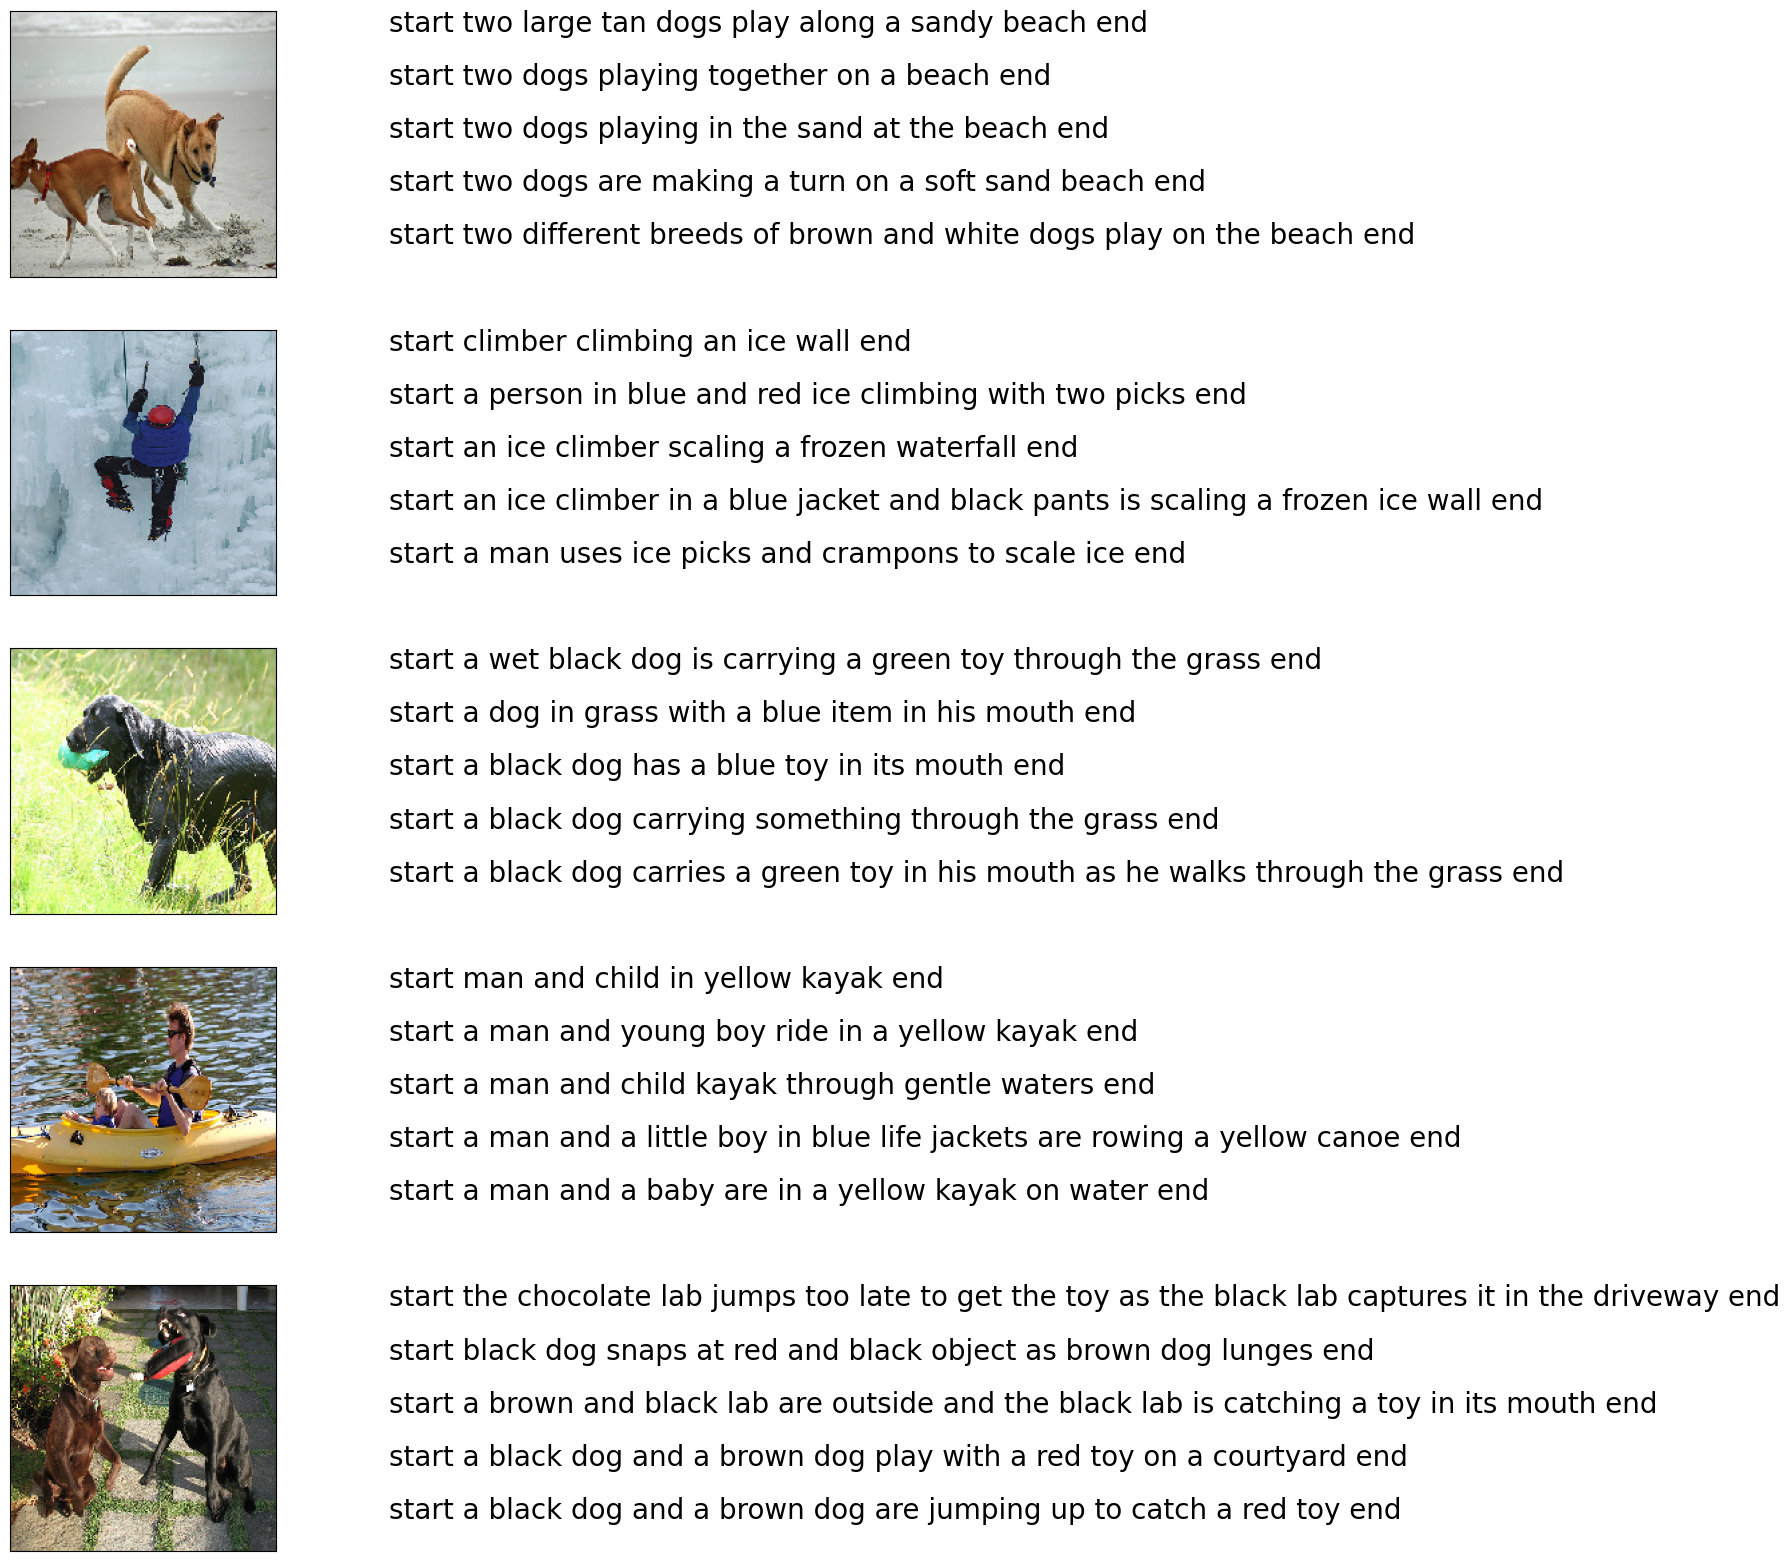

In [7]:
def visualaization(data, num_of_images):
    # We use dictionaries to access captions of each image by its ID
    captions_dictionary = {}
    for item in data[100:100+(num_of_images)*5]:
        image_id, caption = item.split('\t')
        if image_id not in captions_dictionary:
            captions_dictionary[image_id] = []
        captions_dictionary[image_id].append(caption)
    else:
        list_captions = [x for x in captions_dictionary.items()]
    
    count = 1
    fig = plt.figure(figsize=(10,20))
    for filename in list(captions_dictionary.keys()):
        captions = captions_dictionary[filename]
        image_load = load_img(images_directory+filename, target_size=(199,199,3))

        ax = fig.add_subplot(num_of_images,2,count,xticks=[],yticks=[])
        ax.imshow(image_load)
        count += 1

        ax = fig.add_subplot(num_of_images,2,count)
        plt.axis('off')
        ax.plot()
        ax.set_xlim(0,1)
        ax.set_ylim(0,len(captions))
        for i, caption in enumerate(captions):
            ax.text(0,i,caption,fontsize=20)
        count += 1
    plt.show()
    
visualaization(captions_IDs, 5)


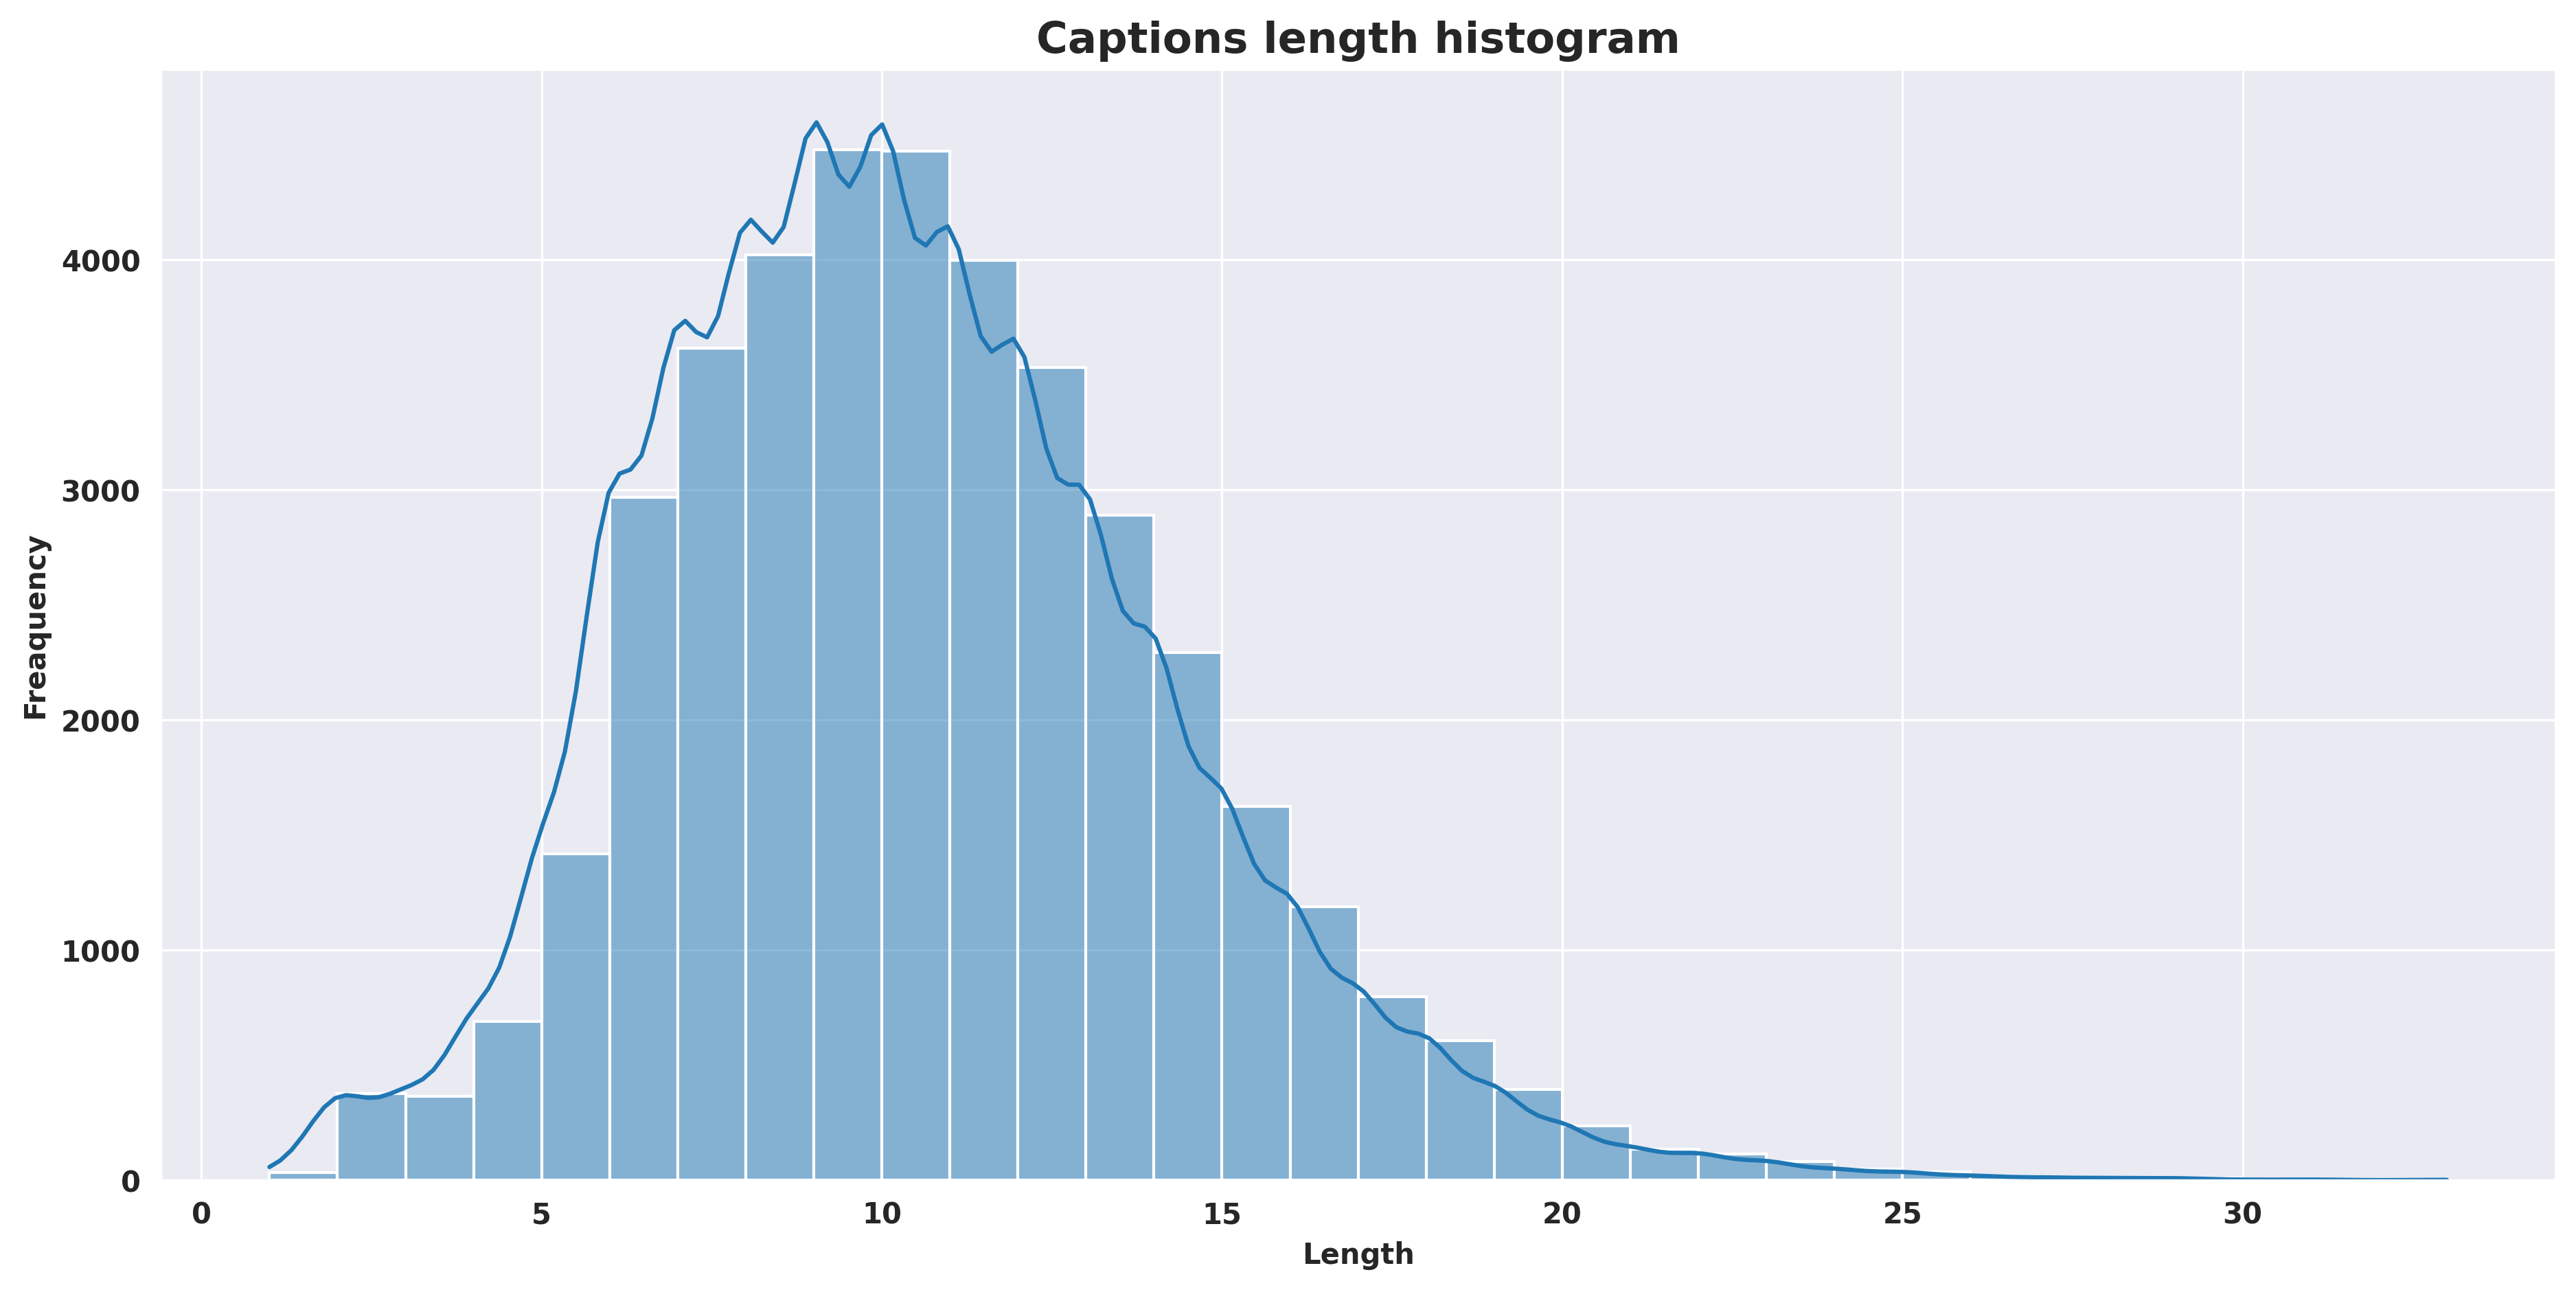

In [8]:
def captions_length(data):
    plt.figure(figsize=(15, 7), dpi=300)
    sns.set_style('darkgrid')
    sns.histplot(x=[len(x.split(' ')) for x in data], kde=True, binwidth=1) 
    plt.title('Captions length histogram', fontsize=15, fontweight='bold')
    plt.xticks(fontweight='bold')
    plt.yticks(fontweight='bold')
    plt.xlabel('Length', fontweight='bold')
    plt.ylabel('Freaquency', fontweight='bold')
    plt.show()
    
captions_length(cleaned_captions)

In [9]:
def word_occurrences(data):
    # Combining all sentences into a single string
    all_text = ' '.join(data)
    # Splitting the text into words and count occurrences
    word_counts = Counter(all_text.split())

    words = list(word_counts.keys())[1:30]
    values = list(word_counts.values())[1:30]

    # Normalize values to be between 0 and 1
    normalized_values = np.array(values) / np.max(values)
    colors = np.array(['rgba(30, 58, 138, {})'.format(0.4 + 0.5 * (value)) for value in normalized_values])

    fig = go.Figure(data=[go.Pie(labels=words, values=values, hole=.6, marker=dict(colors=colors), textinfo='label')])

    fig.update_layout(title_text='Word occurrences in captions (except for letter \'a\')', title_font=dict(size=23, family='Balto'))

    fig.show()
    
word_occurrences(cleaned_captions)

In [10]:
# Tokenizing the captions and creating word-to-index mapping
tokenizer = tokenize_captions(cleaned_captions)
vocab_size = len(tokenizer.word_index) + 1
vocab_size

8586

In [11]:
# Storing all image IDs
all_image_ids = os.listdir(images_directory)

# Splitting image IDs
train_image_ids, val_image_ids = train_test_split(all_image_ids, test_size=0.15, random_state=42)
val_image_ids, test_image_ids = train_test_split(val_image_ids, test_size=0.1, random_state=42)

train_captions, val_captions, test_captions = [], [], []
for caption in captions_IDs:
    image_id, _ = caption.split('\t')
    
    if image_id in train_image_ids:
        train_captions.append(caption)
        
    elif image_id in val_image_ids:
        val_captions.append(caption)        

    elif image_id in test_image_ids:
        test_captions.append(caption)
        
    else:
        print('Unknown image ID !')

train_captions[0], val_captions[0], test_captions[0], len(train_captions)/5, len(val_captions)/5, len(test_captions)/5


('1000268201_693b08cb0e.jpg\tstart a child in a pink dress is climbing up a set of stairs in an entry way end\n',
 '1001773457_577c3a7d70.jpg\tstart a black dog and a spotted dog are fighting end\n',
 '1042590306_95dea0916c.jpg\tstart a man and woman pose for the camera while another man looks on end\n',
 6877.0,
 1092.0,
 122.0)

In [66]:
import numpy as np
import tensorflow as tf
import os
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D

# === Preprocess image ===
def preprocess_image(image_path):
    img = load_img(image_path, target_size=(299, 299))
    img = img_to_array(img)
    img = np.expand_dims(img, axis=0)
    img = preprocess_input(img)
    return img

# === Extract image features ===
def extract_image_features(model, image_path):
    img = preprocess_image(image_path)
    features = model.predict(img, verbose=0)
    return features

# === Load InceptionV3 with your local weights (no top) ===
weights_path = "/kaggle/input/inception_v3_weights/keras/default/1/inception_v3_weights_tf_dim_ordering_tf_kernels_notop.h5"

# Load base model without the top classification layer
base_model = InceptionV3(weights=None, include_top=False, input_shape=(299, 299, 3))
base_model.load_weights(weights_path)

# Add GlobalAveragePooling2D properly
gap_output = GlobalAveragePooling2D()(base_model.output)
# You can use the last convolutional layer's output as the feature vector
inception_model = Model(inputs=base_model.input, outputs=gap_output)

# === Test with one image ===
sample_image_path = "../input/flickr8k/Images/667626_18933d713e.jpg"  # Change if needed
features = extract_image_features(inception_model, sample_image_path)
print("Extracted features shape:", features.shape)


Extracted features shape: (1, 2048)


In [67]:
import os
print(os.listdir("/kaggle/input/inception_v3_weights/keras/default/1"))


['inception_v3_weights_tf_dim_ordering_tf_kernels_notop.h5']


In [68]:
train_image_features, val_image_features, test_image_features = {}, {}, {}  # A Dictionary to store image features with their corresponding IDs       

pbar = tqdm_notebook(total=len(all_image_ids), position=0, leave=True, colour='green') 

for caption in all_image_ids:
    image_id = caption.split('\t')[0]
    image_path = os.path.join(images_directory, image_id)
    image_features = extract_image_features(inception_model, image_path) # Extracting features
    
    if image_id in train_image_ids:
        train_image_features[image_id] = image_features.flatten()  # Flattening the features
        pbar.update(1)
    
    elif image_id in val_image_ids:
        val_image_features[image_id] = image_features.flatten()  # Flattening the features
        pbar.update(1)
    
    elif image_id in test_image_ids:
        test_image_features[image_id] = image_features.flatten()  # Flattening the features
        pbar.update(1)
    
    else:
        print('Unknown image ID !')
    
pbar.close()

  0%|          | 0/8091 [00:00<?, ?it/s]

In [78]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
import tensorflow as tf

# Tokenize the captions (assuming tokenizer is already created and fit)
tokenized_train_captions = tokenizer.texts_to_sequences(train_captions)
tokenized_val_captions = tokenizer.texts_to_sequences(val_captions)
tokenized_captions = tokenizer.texts_to_sequences(captions)

# Compute max caption length from the training set
max_length = max(len(seq) for seq in tokenized_captions)
print("Max caption length:", max_length)

# (Optional) Pad captions if needed later
padded_train_captions = pad_sequences(tokenized_train_captions, maxlen=max_caption_length, padding='post')
padded_val_captions = pad_sequences(tokenized_val_captions, maxlen=max_caption_length, padding='post')

Max caption length: 36


In [79]:
from tensorflow.keras.layers import Input, Dense, Embedding, LSTM, Concatenate
from tensorflow.keras.models import Model

# ✅ Image input (2048-dimensional feature vector)
image_input = Input(shape=(2048,), name='image_input')
image_dense = Dense(256, activation='relu')(image_input)

# ✅ Caption input (max_length should match tokenizer)
caption_input = Input(shape=(max_length,), name='caption_input')
caption_embedding = Embedding(input_dim=vocab_size, output_dim=256, mask_zero=True)(caption_input)
caption_lstm = LSTM(256)(caption_embedding)

# Combine both
decoder = Concatenate()([image_dense, caption_lstm])
output = Dense(vocab_size, activation='softmax')(decoder)

# Build model
caption_model = Model(inputs=[image_input, caption_input], outputs=output)
caption_model.compile(loss='categorical_crossentropy', optimizer='adam')


In [80]:
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tqdm import tqdm
import numpy as np

def data_generator(captions, image_features, tokenizer, max_caption_length, batch_size, vocab_size, verbose=False):
    num_samples = len(captions)
    image_ids = list(image_features.keys())

    while True:
        np.random.shuffle(image_ids)  # Shuffle for each epoch
        for start_idx in range(0, num_samples, batch_size):
            end_idx = min(start_idx + batch_size, num_samples)
            X_images, X_captions, y = [], [], []

            batch_captions = captions[start_idx:end_idx]
            iterator = tqdm(batch_captions, desc="Processing batch", disable=not verbose)

            for caption in iterator:
                image_id, caption_text = caption.split('\t')
                caption_text = caption_text.strip()
                seq = tokenizer.texts_to_sequences([caption_text])[0]

                for i in range(1, len(seq)):
                    in_seq, out_seq = seq[:i], seq[i]
                    in_seq = pad_sequences([in_seq], maxlen=max_caption_length, padding='post')[0]
                    out_seq = to_categorical([out_seq], num_classes=vocab_size)[0]

                    X_images.append(image_features[image_id])
                    X_captions.append(in_seq)
                    y.append(out_seq)

            yield (np.array(X_images), np.array(X_captions)), np.array(y)

        


In [81]:
def count_training_samples(captions, tokenizer):
    count = 0
    for caption in captions:
        _, caption_text = caption.split('\t')
        seq = tokenizer.texts_to_sequences([caption_text.strip()])[0]
        count += max(len(seq) - 1, 1)
    return count

In [85]:
# Defining the CNN output dimension
cnn_output_dim = inception_model.output_shape[1]  # 2048

# Defining batch sizes
batch_size_train = 270
batch_size_val = 150

# Vocab size
vocab_size = tokenizer.num_words or len(tokenizer.word_index) + 1

# Max caption length
max_caption_length = max(len(caption.split()) for caption in cleaned_captions) + 1

# Generators (now fixed with vocab_size)
train_data_generator = data_generator(
    train_captions, train_image_features, tokenizer,
    max_caption_length, batch_size_train, vocab_size
)

val_data_generator = data_generator(
    val_captions, val_image_features, tokenizer,
    max_caption_length, batch_size_val, vocab_size
)

# TF Datasets using output_signature
train_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(train_captions, train_image_features, tokenizer, max_caption_length, batch_size_train, vocab_size),
    output_signature=(
        (
            tf.TensorSpec(shape=(None, cnn_output_dim), dtype=tf.float32),
            tf.TensorSpec(shape=(None, max_caption_length), dtype=tf.int32)
        ),
        tf.TensorSpec(shape=(None, vocab_size), dtype=tf.float32)
    )
)

val_dataset = tf.data.Dataset.from_generator(
    lambda: data_generator(val_captions, val_image_features, tokenizer, max_caption_length, batch_size_val, vocab_size),
    output_signature=(
        (
            tf.TensorSpec(shape=(None, cnn_output_dim), dtype=tf.float32),
            tf.TensorSpec(shape=(None, max_caption_length), dtype=tf.int32)
        ),
        tf.TensorSpec(shape=(None, vocab_size), dtype=tf.float32)
    )
)


In [86]:
# Checking shapes
sample_batch = next(train_data_generator)
print("Training sample batch shapes:")
print("X_images:", sample_batch[0][0].shape)
print("X_captions:", sample_batch[0][1].shape)
print("y:", sample_batch[1].shape)
print('=========================')
sample_batch = next(val_data_generator)
print("Validation sample batch shapes:")
print("X_images:", sample_batch[0][0].shape)
print("X_captions:", sample_batch[0][1].shape)
print("y:", sample_batch[1].shape)

Training sample batch shapes:
X_images: (3230, 2048)
X_captions: (3230, 34)
y: (3230, 8586)
Validation sample batch shapes:
X_images: (1676, 2048)
X_captions: (1676, 34)
y: (1676, 8586)


In [87]:
def build_model(vocab_size, max_caption_length, cnn_output_dim):
    # Encoder Model
    input_image = Input(shape=(cnn_output_dim,), name='Features_Input')
    fe1 = BatchNormalization()(input_image)
    fe2 = Dense(256, activation='relu')(fe1) # Adding a Dense layer to the CNN output to match the decoder output size
    fe3 = BatchNormalization()(fe2)
    
    # Decoder Model
    input_caption = Input(shape=(max_caption_length,), name='Sequence_Input')
    se1 = Embedding(vocab_size, 256, mask_zero=True)(input_caption)
    se2 = LSTM(256)(se1)
    
    # Output
    decoder1 = add([fe3, se2])
    decoder2 = Dense(256, activation='relu')(decoder1)
    outputs = Dense(vocab_size, activation='softmax', name='Output_Layer')(decoder2)

    # Returning The Model
    model = Model(inputs=[input_image, input_caption], outputs=outputs, name='Image_Captioning')
    return model
    
# Building the model
cnn_output_dim = 2048
caption_model = build_model(vocab_size, max_caption_length, cnn_output_dim)

optimizer = Adam(learning_rate=0.01, clipnorm=1.0)
caption_model.compile(loss='categorical_crossentropy', optimizer=optimizer)

caption_model.summary()

Model: "Image_Captioning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Features_Input            │ (None, 2048)           │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_296   │ (None, 2048)           │          8,192 │ Features_Input[0][0]   │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ Sequence_Input            │ (None, 34)             │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_29 (Dense)          │ (None, 256)            │        524,544 │ batch_normalization_2… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ embedding_14 (Embedding)  │ (None, 34, 256)        │      2,198,016 │ Sequence_Input[0][0]   │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ not_equal_14 (NotEqual)   │ (None, 34)             │              0 │ Sequence_Input[0][0]   │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_297   │ (None, 256)            │          1,024 │ dense_29[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ lstm_14 (LSTM)            │ (None, 256)            │        525,312 │ embedding_14[0][0],    │
│                           │                        │                │ not_equal_14[0][0]     │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ add_7 (Add)               │ (None, 256)            │              0 │ batch_normalization_2… │
│                           │                        │                │ lstm_14[0][0]          │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dense_30 (Dense)          │ (None, 256)            │         65,792 │ add_7[0][0]            │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ Output_Layer (Dense)      │ (None, 8586)           │      2,206,602 │ dense_30[0][0]         │
└───────────────────────────┴────────────────────────┴────────────────┴────────────────────────┘

 Total params: 5,529,482 (21.09 MB)

 Trainable params: 5,524,874 (21.08 MB)

 Non-trainable params: 4,608 (18.00 KB)

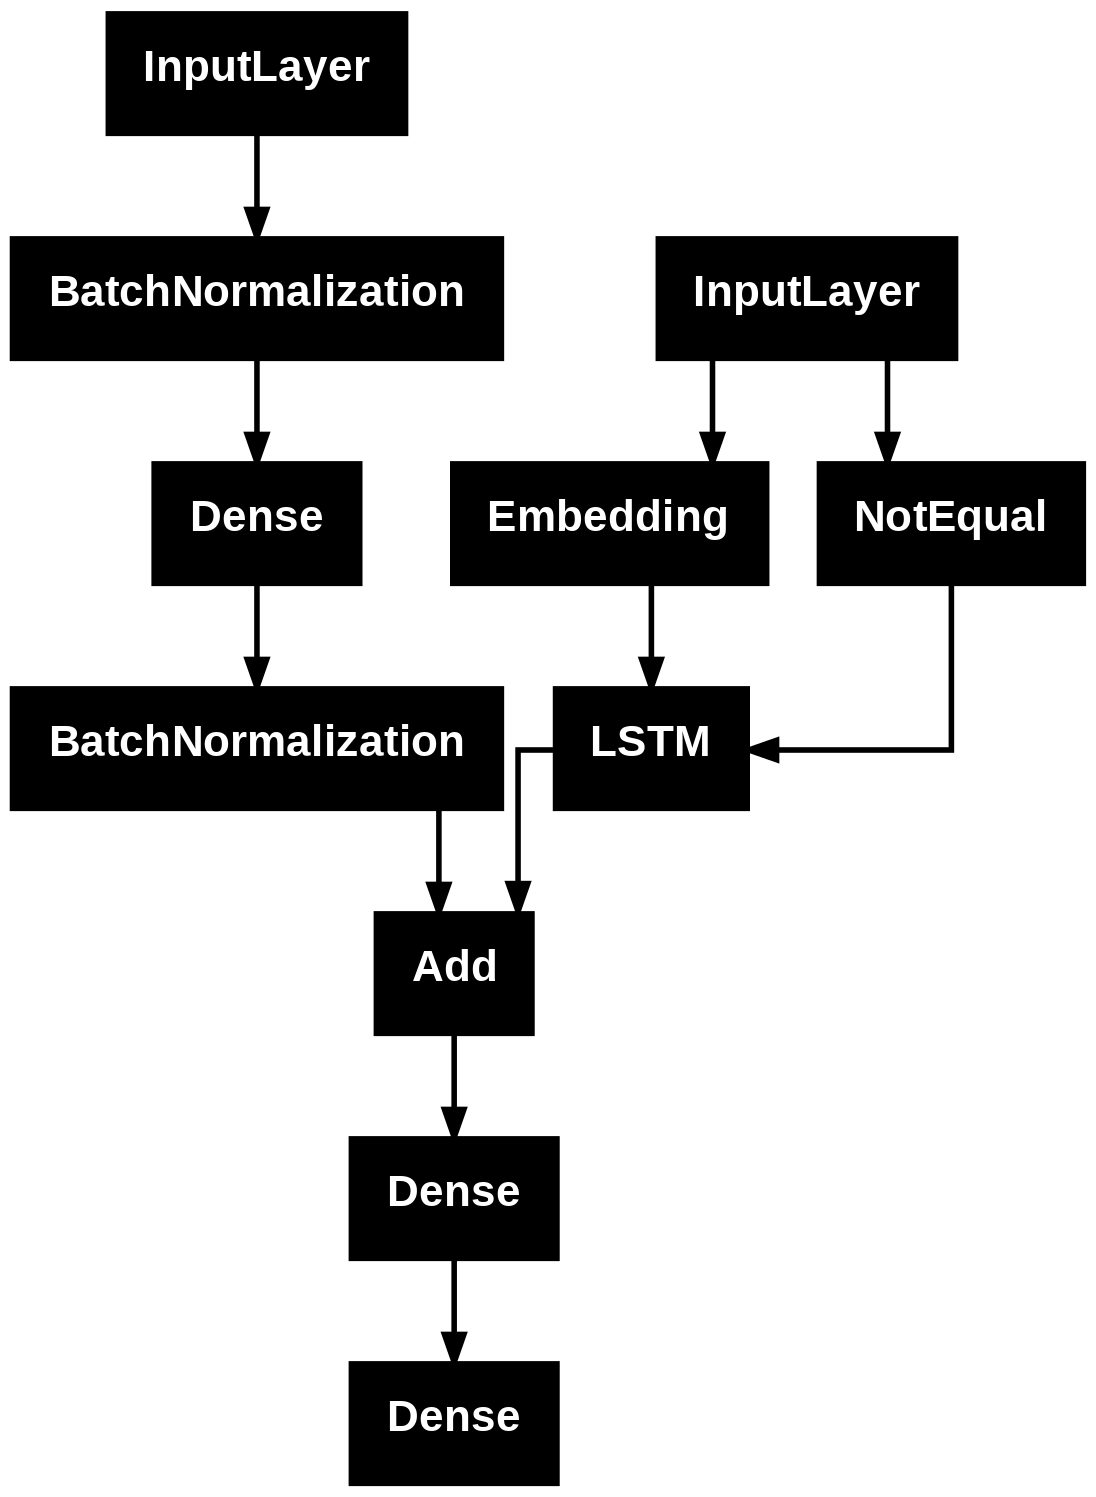

In [88]:
plot_model(caption_model)

In [100]:
from tensorflow.keras.callbacks import EarlyStopping, LearningRateScheduler
import numpy as np

# # Define initial learning rate
initial_lr = 0.01

# # Early stopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# # ✅ Custom learning rate schedule function
def lr_scheduler(epoch):
    return float(initial_lr * np.exp(-0.1 * epoch))

# # ✅ Learning rate scheduler callback
lr_callback = LearningRateScheduler(lr_scheduler)

# Define your batch size and number of epochs
BATCH_SIZE = 64
EPOCHS = 10

# Calculate correct number of steps per epoch (rounded down)
steps_per_epoch = 127
validation_steps = len(val_captions) // BATCH_SIZE

# Train the model
history = caption_model.fit(
    train_dataset,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=val_dataset,
    validation_steps=validation_steps,
    callbacks=[early_stopping, lr_callback],
)


Epoch 1/10
127/127 ━━━━━━━━━━━━━━━━━━━━ 674s 5s/step - loss: 2.5956 - val_loss: 3.2909 - learning_rate: 0.0100
Epoch 2/10
127/127 ━━━━━━━━━━━━━━━━━━━━ 668s 5s/step - loss: 2.4507 - val_loss: 3.3464 - learning_rate: 0.0090
Epoch 3/10
127/127 ━━━━━━━━━━━━━━━━━━━━ 668s 5s/step - loss: 2.2728 - val_loss: 3.4702 - learning_rate: 0.0082
Epoch 4/10
127/127 ━━━━━━━━━━━━━━━━━━━━ 668s 5s/step - loss: 2.1295 - val_loss: 3.5974 - learning_rate: 0.0074


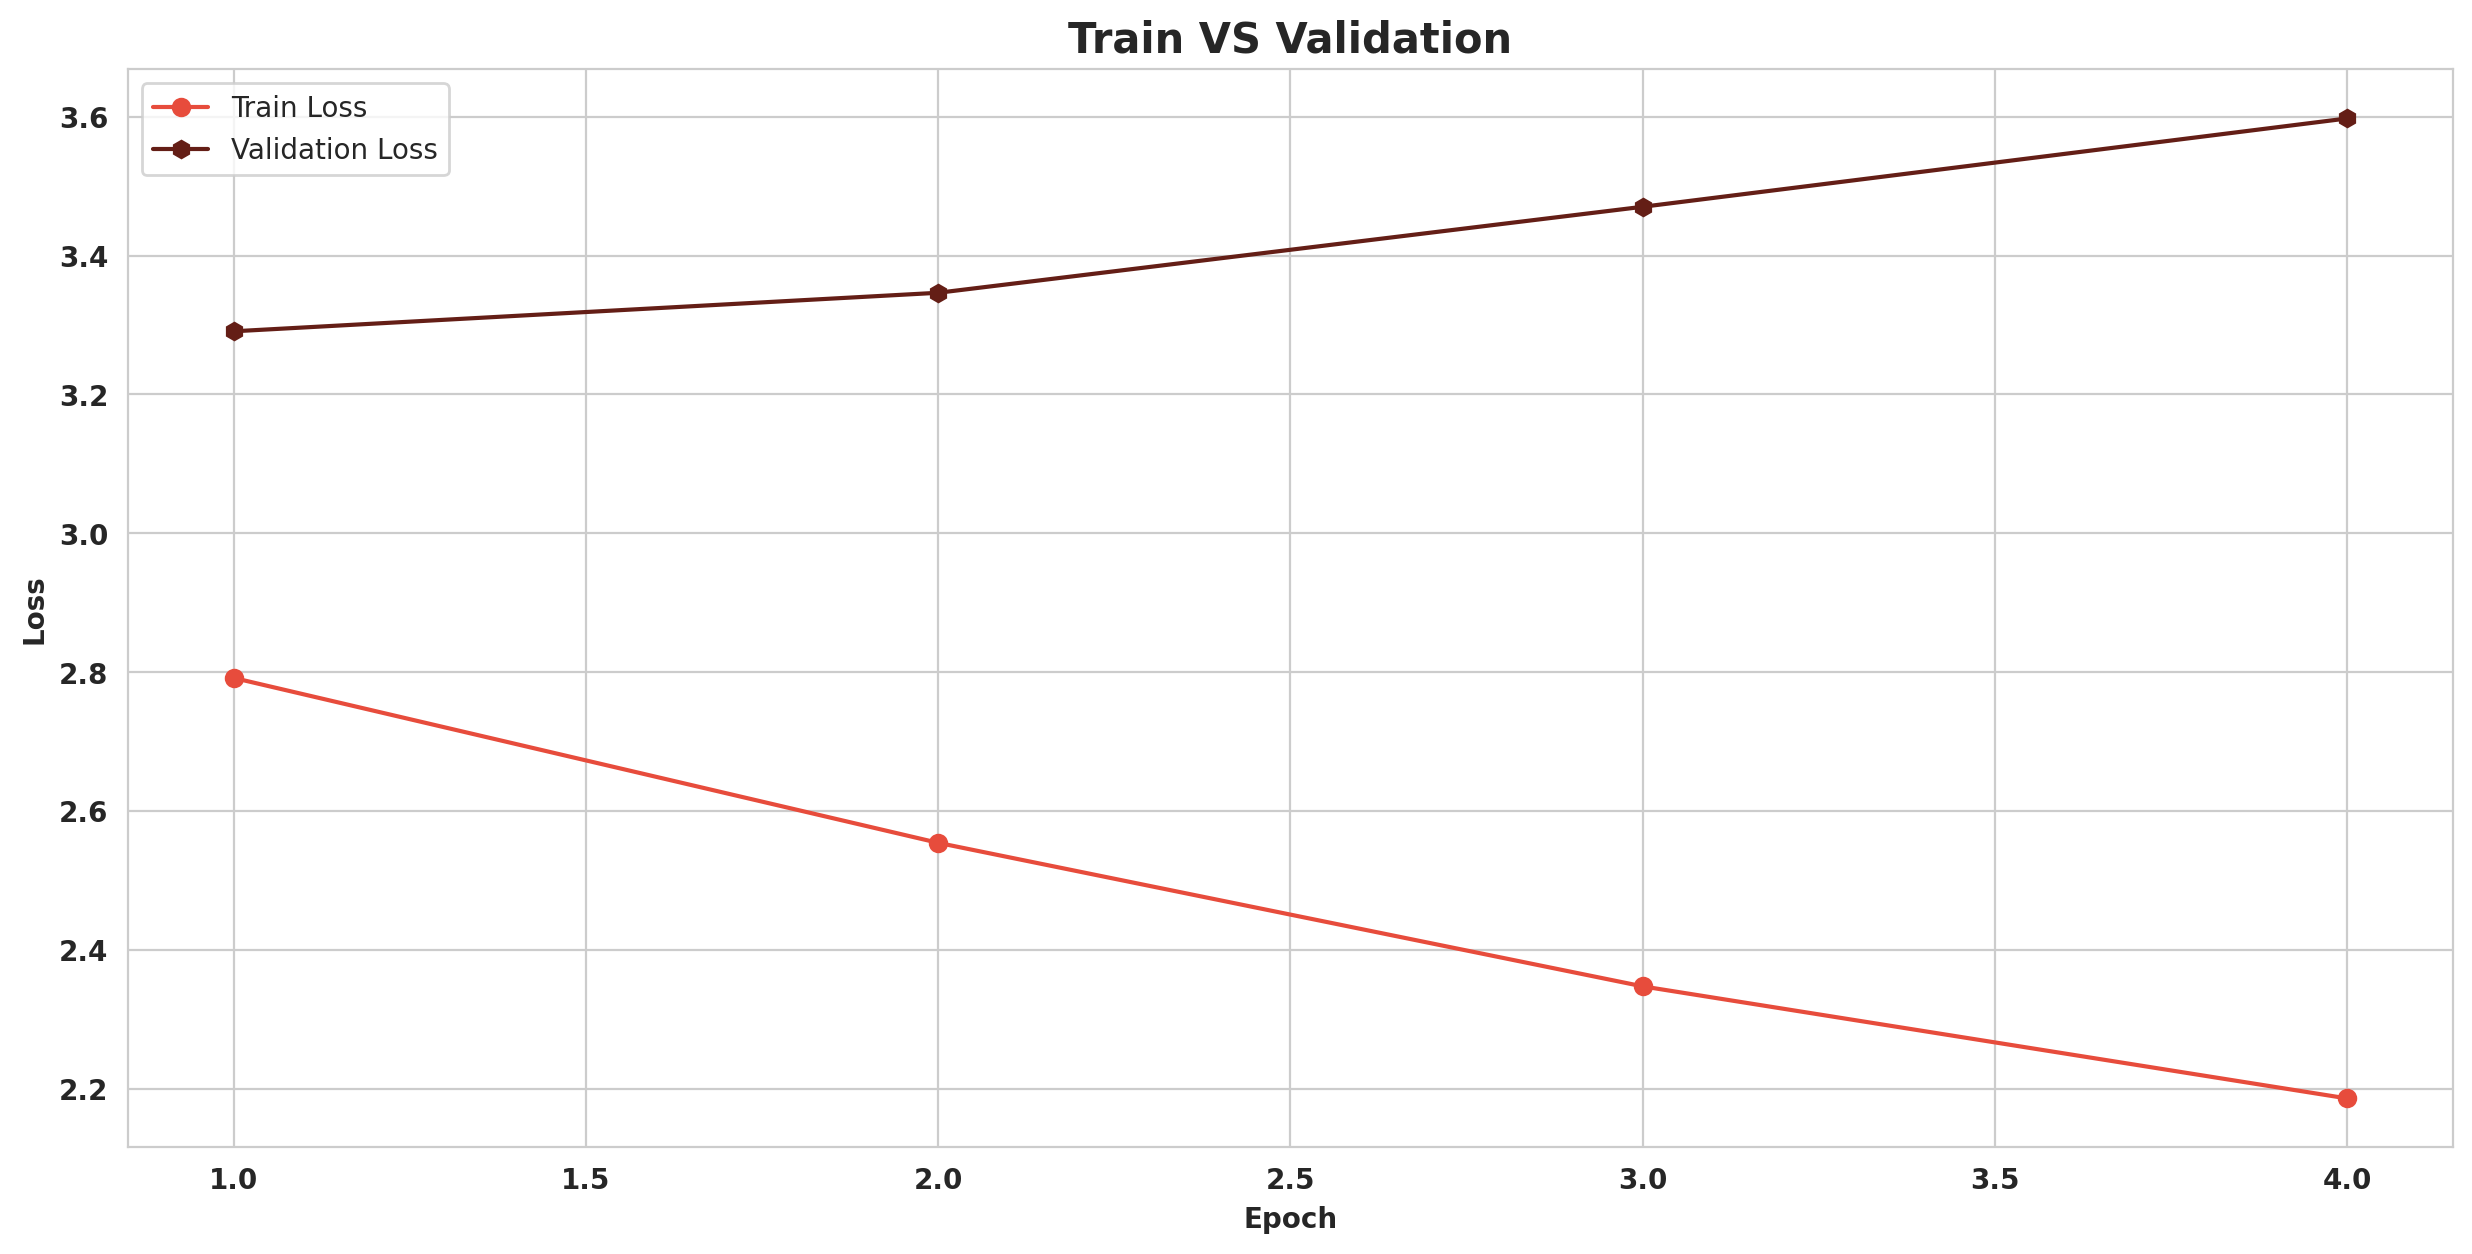

In [101]:
plt.figure(figsize=(15, 7), dpi=200)
sns.set_style('whitegrid')
plt.plot([x+1 for x in range(len(history.history['loss']))], history.history['loss'], color='#E74C3C', marker='o')
plt.plot([x+1 for x in range(len(history.history['loss']))], history.history['val_loss'], color='#641E16', marker='h')
plt.title('Train VS Validation', fontsize=15, fontweight='bold')
plt.xticks(fontweight='bold')
plt.yticks(fontweight='bold')
plt.xlabel('Epoch', fontweight='bold')
plt.ylabel('Loss', fontweight='bold')
plt.legend(['Train Loss', 'Validation Loss'], loc='best')
plt.show()

In [102]:
def greedy_generator(image_features): # A function to generate captions
    # Each caption is started with the word 'start'
    in_text = 'start '
    for _ in range(max_caption_length):
        sequence = tokenizer.texts_to_sequences([in_text])[0]
        sequence = pad_sequences([sequence], maxlen=max_caption_length).reshape((1,max_caption_length))
        prediction = caption_model.predict([image_features.reshape(1,cnn_output_dim), sequence], verbose=0)
        idx = np.argmax(prediction)
        word = tokenizer.index_word[idx]
        # Adding the predicted word to the sequence
        in_text += ' ' + word
        # When the model returns the word 'end' (which is the end word), the generating loop must be stopped 
        if word == 'end':
            break
            
    in_text = in_text.replace('start ', '')
    in_text = in_text.replace(' end', '')
    
    return in_text

In [103]:
def beam_search_generator(image_features, K_beams = 3, log = False):
    start = [tokenizer.word_index['start']]
    
    start_word = [[start, 0.0]]
    
    for _ in range(max_caption_length):
        temp = []
        for s in start_word:
            # Sequence of most probable words based on the previous steps
            sequence  = pad_sequences([s[0]], maxlen=max_caption_length).reshape((1,max_caption_length))
            
            preds = caption_model.predict([image_features.reshape(1,cnn_output_dim), sequence], verbose=0)
            
            # Sorting predictions by the probability and taking the last K_beams items.
            word_preds = np.argsort(preds[0])[-K_beams:]
            
            # Getting the top <K_beams>(n) predictions and creating a 
            #                              new list so as to put them via the model again.
            for w in word_preds:
                
                next_cap, prob = s[0][:], s[1]
                next_cap.append(w)
                if log:
                    prob += np.log(preds[0][w]) # assign a probability to each K words
                else:
                    prob += preds[0][w]
                temp.append([next_cap, prob])
                
        start_word = temp
        # Sorting according to the probabilities
        start_word = sorted(start_word, reverse=False, key=lambda l: l[1])

        # Getting the top words
        start_word = start_word[-K_beams:]
    
    start_word = start_word[-1][0]
    captions_ = [tokenizer.index_word[i] for i in start_word]

    final_caption = []
    
    for i in captions_:
        if i != 'end':
            final_caption.append(i)
        else:
            break
    
    final_caption = ' '.join(final_caption[1:])
    return final_caption

In [105]:
# Calculates BLEU score of predictions
def BLEU_score(actual, greedy, beam_search):
    # Calculating the BLEU score by comparing the predicted caption with five actual captions.
    score_greedy_1 = corpus_bleu(actual, greedy, weights=(0.3, 0.3, 0.3, 0))
    score_greedy_2 = corpus_bleu(actual, greedy, weights=(0.25, 0.25, 0.25, 0.25))
    score_BS_1 = corpus_bleu(actual, beam_search, weights=(0.3, 0.3, 0.3, 0))
    score_BS_2 = corpus_bleu(actual, beam_search, weights=(0.25, 0.25, 0.25, 0.25))
    
    return [
        (f'BLEU-2 Greedy: {round(score_BS_2, 5)}'),
        (f'BLEU-1 Greedy: {round(score_BS_1, 5)}'),
        (f'Greedy: {greedy[0]}'),
        (f'BLEU-2 Beam Search: {round(score_greedy_2, 5)}'),
        (f'BLEU-1 Beam Search: {round(score_greedy_1, 5)}'),
        (f'Beam Search:  {beam_search[0]}')
    ]

In [106]:
# A dictionary to access actual captions of each image by its ID
test_actual_captions = {}
for item in test_captions:
    image_id, caption = item.split('\t')
    if image_id not in test_actual_captions:
        test_actual_captions[image_id] = []
    test_actual_captions[image_id].append(caption)

In [107]:
# Generating captions
generated_captions = {}

pbar = tqdm_notebook(total=len(test_image_features), position=0, leave=True, colour='green')
for image_id in test_image_features:
    cap = greedy_generator(test_image_features[image_id])
    generated_captions[image_id] = cap
    pbar.update(1)
    
pbar.close()

  0%|          | 0/122 [00:00<?, ?it/s]

In [109]:
def visualization(data, greedy_caps, beamS_generator, num_of_images):
    import matplotlib.pyplot as plt
    from tensorflow.keras.utils import load_img
    import numpy as np

    keys = list(data.keys())  # List of all test images
    images = [np.random.choice(keys) for _ in range(num_of_images)]  # Randomly selected images
    
    count = 1
    fig = plt.figure(figsize=(6, 20))    
    
    for filename in images:
        image_load = load_img(images_directory + filename, target_size=(199, 199, 3))
        ax = fig.add_subplot(num_of_images, 2, count, xticks=[], yticks=[])
        ax.imshow(image_load)
        count += 1

        # Get captions
        greedy_cap = greedy_caps[filename]
        beam_cap = beamS_generator(test_image_features[filename])
        
        ax = fig.add_subplot(num_of_images, 2, count)
        plt.axis('off')
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 2)
        
        # Only show captions
        ax.text(0, 1, f"Beam Search:  {beam_cap}", fontsize=10)
        ax.text(0, 0, f"Greedy:       {greedy_cap}", fontsize=10)
        
        count += 1
    
    plt.tight_layout()
    plt.show()


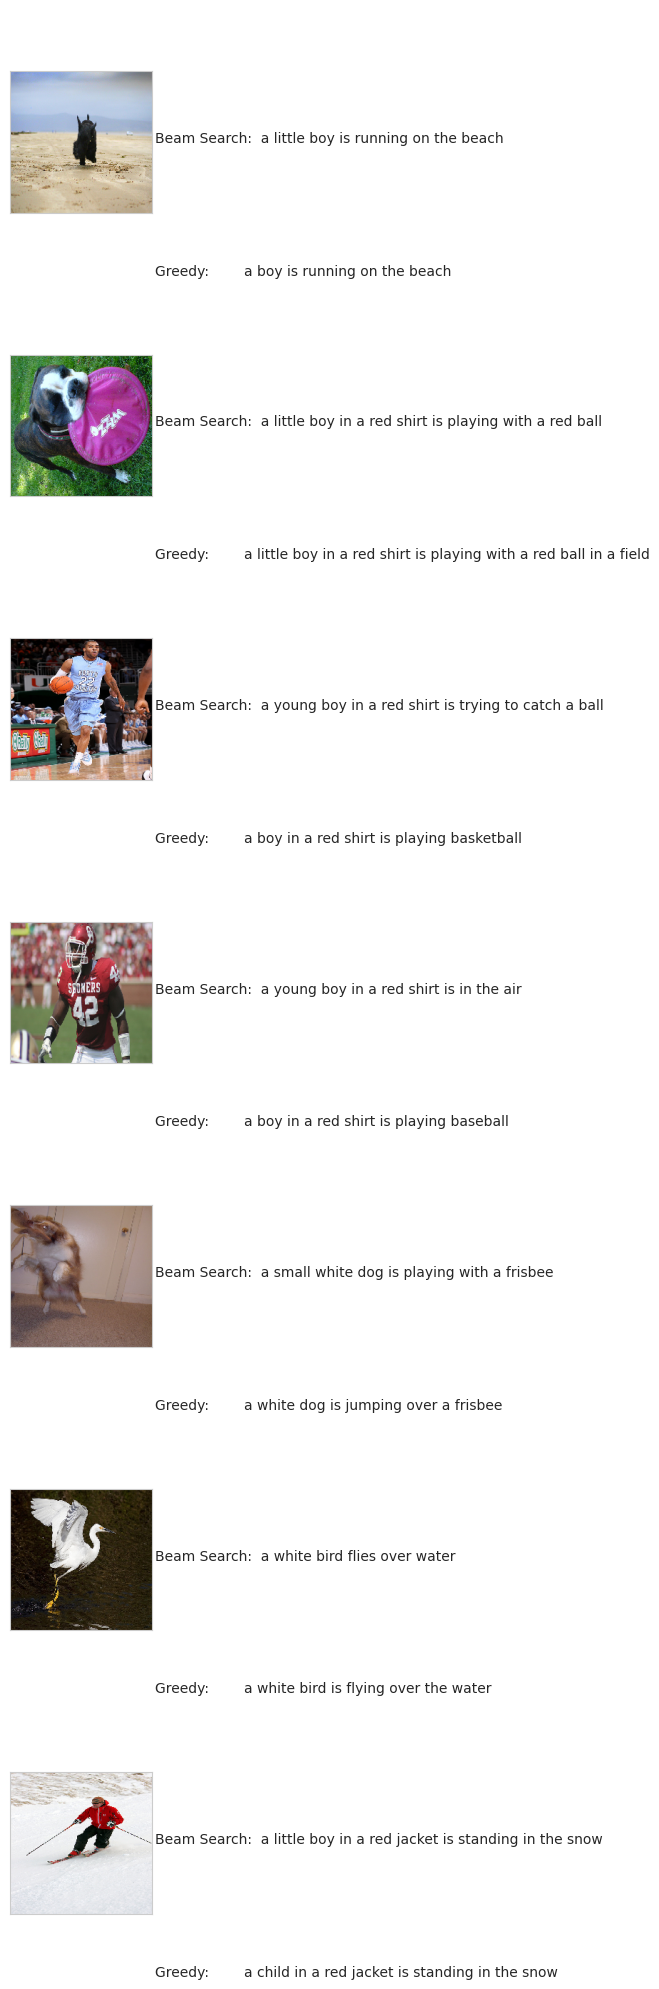

In [110]:
visualization(test_actual_captions, generated_captions, beam_search_generator, num_of_images=7)


In [111]:
def visualization(data, greedy_caps, num_of_images):
    import matplotlib.pyplot as plt
    from tensorflow.keras.utils import load_img
    import numpy as np

    keys = list(data.keys())  # List of all test images
    images = [np.random.choice(keys) for _ in range(num_of_images)]  # Randomly selected images

    count = 1
    fig = plt.figure(figsize=(6, 20))

    for filename in images:
        # Get actual caption(s), remove tokens
        actual_cap = data[filename]
        actual_cap = [x.replace("start ", "").replace(" end", "") for x in actual_cap]

        # Use only the first reference caption (for simplicity)
        actual = actual_cap[0] if len(actual_cap) > 0 else "N/A"
        generated = greedy_caps.get(filename, "N/A")  # fallback if not found

        # Load and show image
        image_load = load_img(images_directory + filename, target_size=(199, 199, 3))
        ax = fig.add_subplot(num_of_images, 2, count, xticks=[], yticks=[])
        ax.imshow(image_load)
        count += 1

        # Add caption text
        ax = fig.add_subplot(num_of_images, 2, count)
        plt.axis('off')
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 2)

        ax.text(0, 1, f"Test Actual Caption:   {actual}", fontsize=10)
        ax.text(0, 0, f"Generated Caption:     {generated}", fontsize=10)

        count += 1

    plt.tight_layout()
    plt.show()


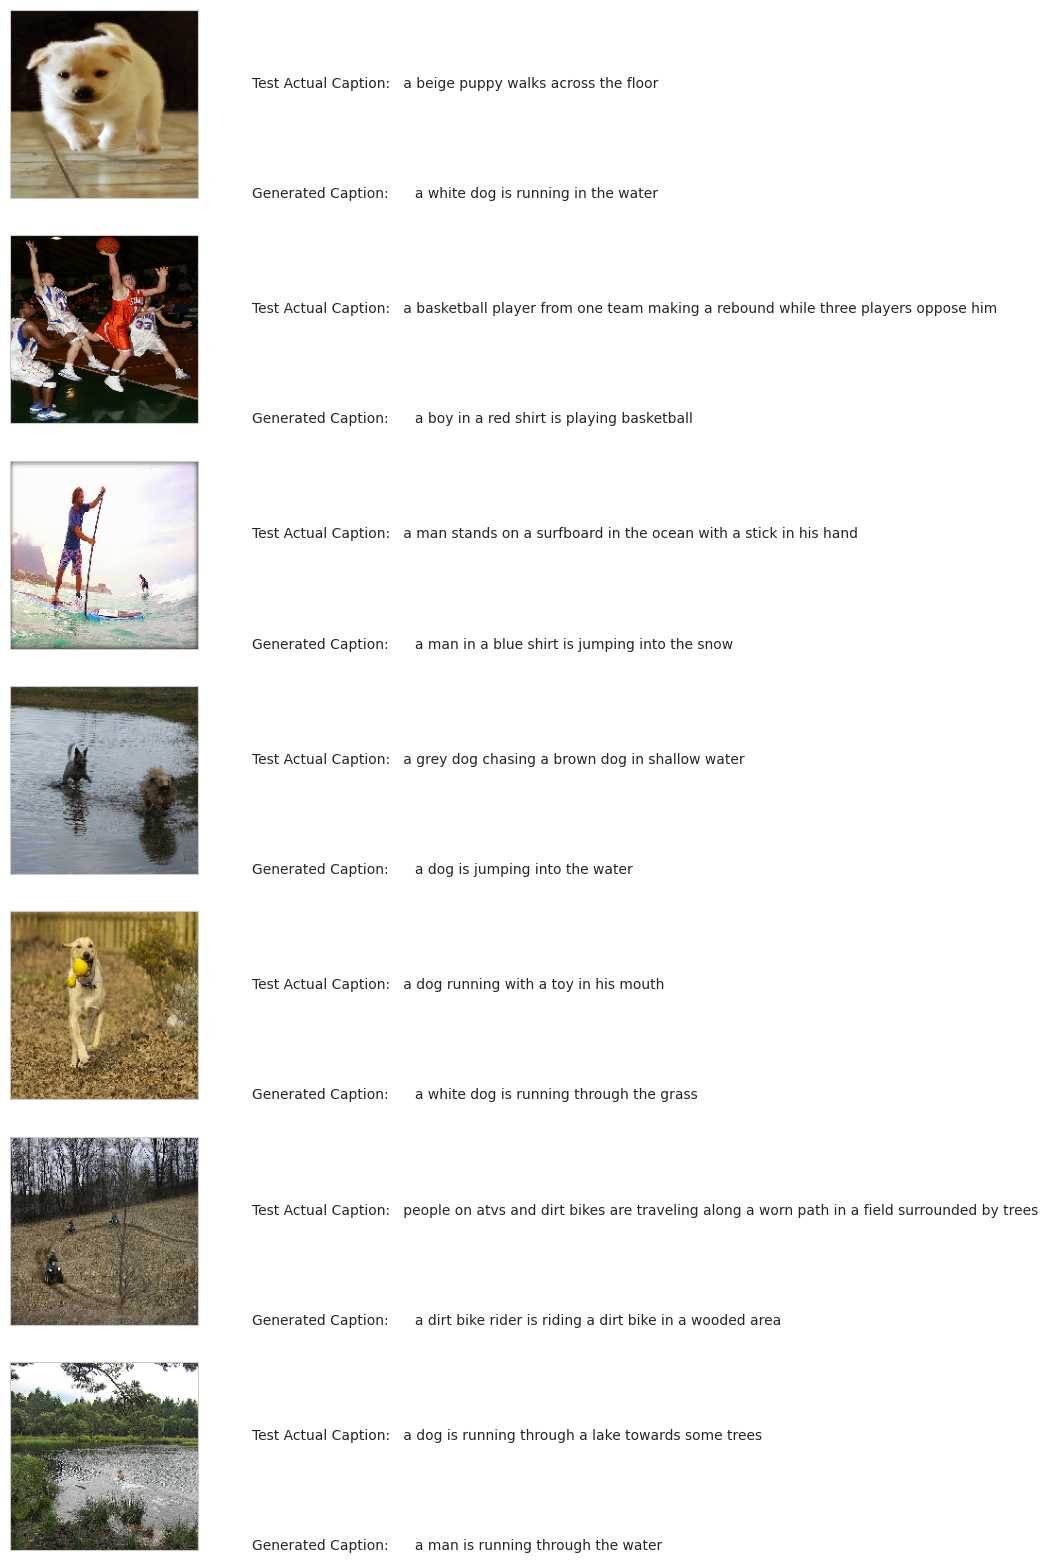

In [112]:
visualization(test_actual_captions, generated_captions, num_of_images=7)


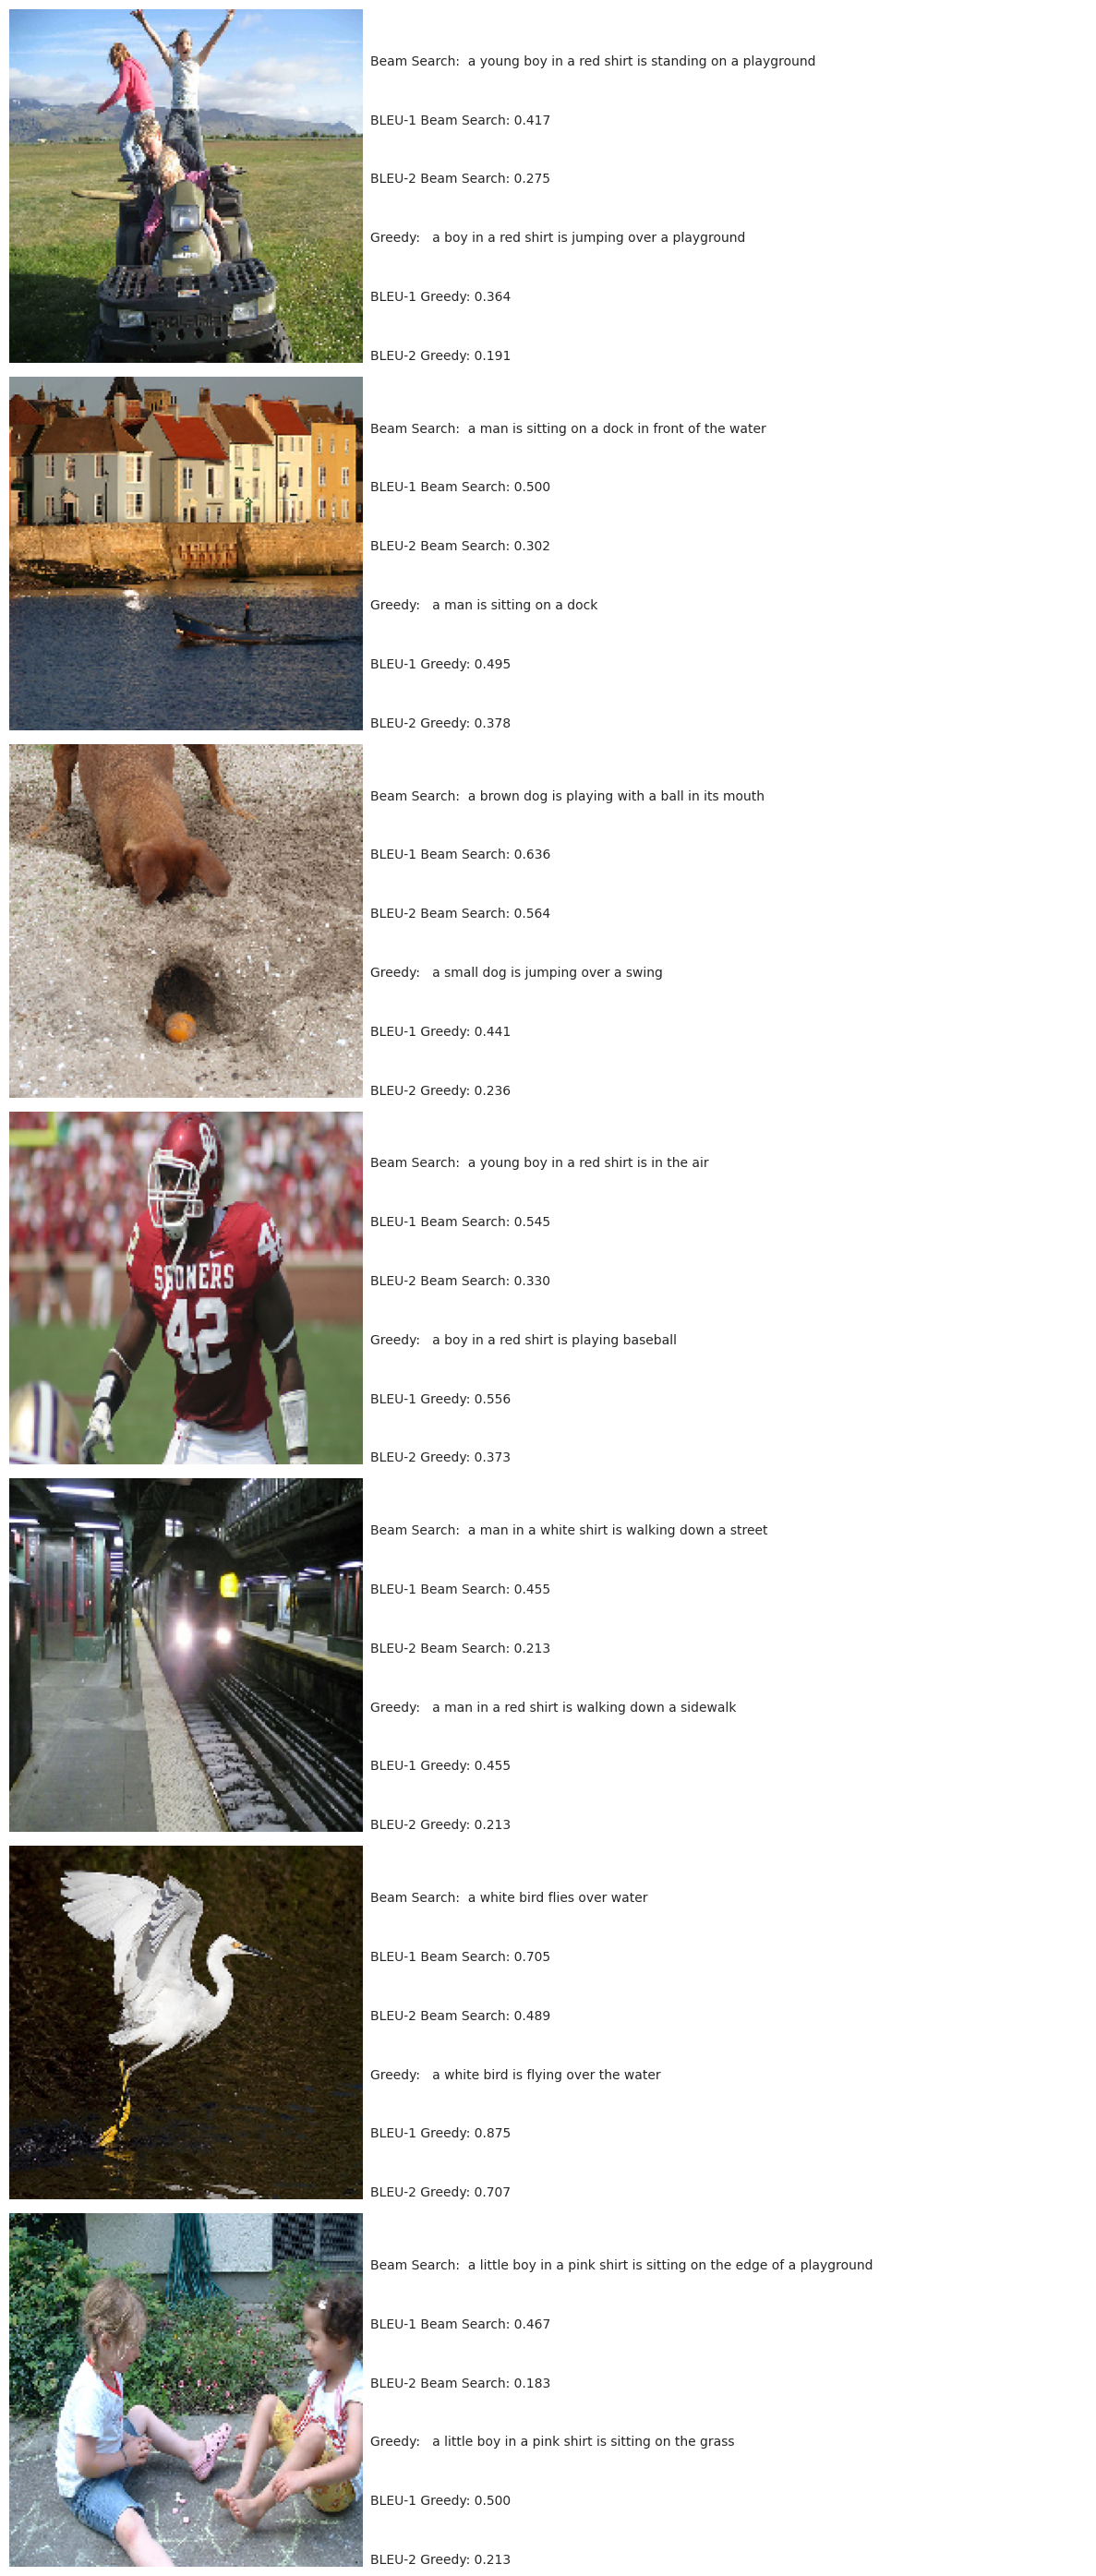

In [132]:
import numpy as np
import matplotlib.pyplot as plt
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.tokenize import word_tokenize
from keras.utils import load_img
import matplotlib.gridspec as gridspec

# BLEU evaluation
def BLEU_score(actual_list, greedy_list, beam_list):
    results = []
    smoothie = SmoothingFunction().method4

    for refs, greedy, beam in zip(actual_list, greedy_list, beam_list):
        refs_tokenized = [word_tokenize(ref.lower()) for ref in refs]
        greedy_tokenized = word_tokenize(greedy.lower())
        beam_tokenized = word_tokenize(beam.lower())

        bleu1_greedy = sentence_bleu(refs_tokenized, greedy_tokenized, weights=(1, 0, 0, 0), smoothing_function=smoothie)
        bleu2_greedy = sentence_bleu(refs_tokenized, greedy_tokenized, weights=(0.5, 0.5, 0, 0), smoothing_function=smoothie)
        bleu1_beam = sentence_bleu(refs_tokenized, beam_tokenized, weights=(1, 0, 0, 0), smoothing_function=smoothie)
        bleu2_beam = sentence_bleu(refs_tokenized, beam_tokenized, weights=(0.5, 0.5, 0, 0), smoothing_function=smoothie)

        results.append([
            f"Beam Search:  {beam}",
            f"BLEU-1 Beam Search: {bleu1_beam:.3f}",
            f"BLEU-2 Beam Search: {bleu2_beam:.3f}",
            f"Greedy:  {greedy}",
            f"BLEU-1 Greedy: {bleu1_greedy:.3f}",
            f"BLEU-2 Greedy: {bleu2_greedy:.3f}"
        ])
    return results


# Visualization function with clean layout
def visualization(data, greedy_caps, beamS_generator, evaluator, num_of_images):
    keys = list(data.keys())
    images = [np.random.choice(keys) for _ in range(num_of_images)]

    fig = plt.figure(figsize=(12, num_of_images * 4))
    gs = gridspec.GridSpec(num_of_images, 2, width_ratios=[1, 2])
    
    for i, filename in enumerate(images):
        # Reference captions
        actual_cap = data[filename]
        actual_cap = [x.replace("start ", "").replace(" end", "") for x in actual_cap]

        # Generate captions
        greedy_cap = greedy_caps[filename]
        beam_cap = beamS_generator(test_image_features[filename])

        # Compute BLEU scores
        scores = evaluator([actual_cap], [greedy_cap], [beam_cap])[0]

        # Show image
        img = load_img(images_directory + filename, target_size=(199, 199, 3))
        ax_img = plt.subplot(gs[i, 0])
        ax_img.imshow(img)
        ax_img.axis('off')

        # Show captions and scores
        ax_txt = plt.subplot(gs[i, 1])
        ax_txt.axis('off')
        ax_txt.set_xlim(0, 1)
        ax_txt.set_ylim(0, len(scores))
        for j, line in enumerate(scores[::-1]):
            ax_txt.text(0, j, line, fontsize=10, verticalalignment='bottom')

    plt.tight_layout()
    plt.show()
# Usage:
visualization(test_actual_captions, generated_captions, beam_search_generator, BLEU_score, 7)
